In [3]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
from IPython.display import Latex
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_model_new/my_modules/')

from scipy.stats import uniform_direction
from reverse_orbit import reverse_orbit
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
sys.path.append('/suphys/aani0116/Work/minicluster_tidal/stellar')
from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
import corner
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [4]:
bmin=1e-9
bmax=1e-4
np.logspace(np.log10(bmin),np.log10(bmax),6)


array([1.e-09, 1.e-08, 1.e-07, 1.e-06, 1.e-05, 1.e-04])

In [5]:
def stellar_energy(N,M,R,v,its_sum):
    bmin=1e-6
    bmax=1e-4
    b=np.random.uniform(1e-6, 1e-4,N) #is this a good choice?
    print(b)
    plt.hist(b,bins=np.logspace(np.log10(bmin),np.log10(bmax),10))
    #plt.hist(b,bins=np.linspace(bmin,bmax,10))

    plt.xscale('log')
    plt.show()
    E=((4*agama.G*agama.G*M*0.27*R*R)/((b**4)*v**2)*3)
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum

In [6]:
E_bin=np.logspace(-34,-12,23)
E=[]
for i in range(3):
    E.append(stellar_energy(int(N_encounter_with_star),1e-14,1e-14,220,1))
plt.hist(E,bins=E_bin)
plt.xscale('log')

NameError: name 'N_encounter_with_star' is not defined

In [43]:
r=np.logspace(-16,-1,16)


In [44]:
def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

mc_time_center, mc_orbit_center = agama.orbit(ic=[1.0,0.0,0.0,0.0,0.0,220.0], potential=pot_mw, time=1e-2,timestart=0,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center,b_max=1e-4)
print(N_encounter_with_star)
compute_rmin(mc_time_center,mc_orbit_center)

12095.000314491033


np.float64(8.626175958433048e-07)

In [47]:
def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

mc_time_center, mc_orbit_center = agama.orbit(ic=[1.0,0.0,0.0,0.0,0.0,220.0], potential=pot_mw, time=1e-2,timestart=0,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center,b_max=1e-4)
print(N_encounter_with_star)
compute_rmin(mc_time_center,mc_orbit_center)

12095.000314491033


np.float64(9.092787842011462e-07)

np.float64(3.029620552363595e-06)

In [48]:
def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)
def compute_rmin(t, xv, N_thresh=1):
    I = np.trapezoid(
        stellar_rho_total(xv[:,0], xv[:,1], xv[:,2])
        * np.linalg.norm(xv[:, 3:], axis=1) * np.pi,
        t
    )
    return np.sqrt(N_thresh / I)
def stellar_energy(N,M,R,v,rmin,its_sum):
        b=np.random.uniform(rmin, 1e-4,N) #is this a good choice?
        E=((4*agama.G*agama.G*M*0.27*R*R)/((b**4)*v**2)*3)
        E_sum=np.sum(E)
        E_rms_sum=np.sum(np.sqrt(E))**2
        if its_sum:
            return E_sum
        else:
            return E_rms_sum


In [49]:
mc=Minicluster(mass=get_mass(), delta=50, concentration=10)
mc.mass,mc.radius

(2.190008217662621e-10, 4.847466501278312e-11)

np.float64(215.1797149542045)

In [32]:
mc_time_center, mc_orbit_center = agama.orbit(ic=[0.001,0.001,0.0,10.0,10.0,220.0], potential=pot_mw, time=1e-2,timestart=0,dtype=float, trajsize=100, accuracy=1e-16,verbose=False)


In [38]:
def N_encounter_diff(t,xv, b_max,b_min): #stellar_rho_total use the better model

    return int(np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)),int(np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_min**2,t))

N_encounter_diff(mc_time_center, mc_orbit_center,1e-4,1e-6)


(1067, 0)

In [34]:
for rmin in r:
    def N_encounter_new(t,xv, b_max=1e-4): #stellar_rho_total use the better model
        return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)
    mc_time_center, mc_orbit_center = agama.orbit(ic=[8.0,1.0,0.0,0.0,0.0,220.0], potential=pot_mw, time=1e-2,timestart=0,dtype=float, trajsize=100, accuracy=1e-16,verbose=False)
    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center,b_max=1e-4)
    #print(rmin,N_encounter_with_star)

    def stellar_energy(N,M,R,v,its_sum):
        b=np.random.uniform(rmin, 1e-4,N) #is this a good choice?
        E=((4*agama.G*agama.G*M*0.27*R*R)/((b**4)*v**2)*3)
        E_sum=np.sum(E)
        E_rms_sum=np.sum(np.sqrt(E))**2
        if its_sum:
            return E_sum
        else:
            return E_rms_sum

    print(stellar_energy(int(N_encounter_with_star),1e-14,1e-14,220,1))

1.049940751945539e-28
3.202275132774469e-29
1.069320321656641e-25
3.079453760406837e-29
1.0753067037031362e-22
1.4486439171490143e-29
1.1719021525513394e-30
1.0993300840287483e-26
1.8133750642653295e-29
3.516810560163397e-30
4.58843811300169e-33
4.578192369184459e-36
1.3212537888535375e-38
5.048595744017501e-40
4.610942036021424e-41
1.9116303506396093e-41


np.float64(10308.303553788222)

In [12]:
col_time=1e-2/N_encounter_with_star
col_time

np.float64(9.175389827310524e-06)

In [13]:
its_sum=col_time<dynamical_time(1e-14,1e-14)
its_sum


np.False_

In [ ]:
delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)


In [35]:
import numpy as np

x, y = np.meshgrid(np.arange(0, 10), np.arange(0, 10))
pts = np.column_stack([x.ravel(), y.ravel()])
# nearest-neighbor distance = 1 exactly

In [14]:
import numpy as np

n = 10
x, y = np.meshgrid(np.arange(n), np.arange(n))
pts = np.column_stack([x.ravel(), y.ravel()]).astype(float)
pts += np.random.uniform(-0.2, 0.2, pts.shape)  # small jitter

In [15]:
import numpy as np

N = 100
target_nn = 1.0
rho = 1 / (2*target_nn)**2      # = 0.25
L = np.sqrt(N / rho)           # box side length
pts = np.random.uniform(0, L, size=(N, 2))

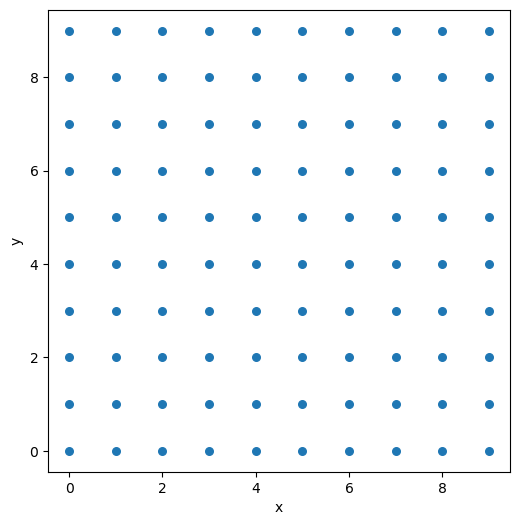

In [36]:
plt.figure(figsize=(6, 6))
plt.scatter(pts[:, 0], pts[:, 1], s=30)
plt.gca().set_aspect('equal')   # so distances look right
plt.xlabel('x')
plt.ylabel('y')
plt.show()

